# Labeling Regression Data Using K-Means Clustering

Mục tiêu của notebook này là sử dụng thuật toán K-means để gán nhãn
(pseudo-labeling) cho dữ liệu hồi quy.

Ý tưởng chính:

- Sử dụng dữ liệu đã có nhãn để xây dựng không gian đặc trưng.
- Áp dụng K-means Clustering trên feature space.
- Gán mỗi quan sát vào một cụm (cluster).
- Tính giá trị trung bình của biến mục tiêu (`int_rate`) trong từng cụm.
- Gán nhãn cho dữ liệu chưa có nhãn dựa trên giá trị trung bình của cụm mà nó thuộc về.

---

1. Load Preprocessed Dataset
2. Create Labeled and Unlabeled Data
3. Prepare Features for Clustering
4. Standardize Numerical Features
5. Apply K-Means Clustering
6. Calculate Mean `int_rate` for Each Cluster
7. Generate Pseudo Labels for Unlabeled Data
8. Evaluate Labeling Results
9. Compare Labeling Methods
10. Evaluate Pseudo Labeling Performance

##### 1. Load Preprocessed Dataset

In [1]:
import pandas as pd

df = pd.read_csv("../loan_preprocessed.csv")

print(df.shape)
df.head()

(1000, 13)


,all_util,bc_open_to_buy,percent_bc_gt_75,bc_util,annual_inc,loan_amnt,dti,term,grade,sub_grade,verification_status,home_ownership,int_rate
0,73.000000,8.992557,50.0,57.9,11.097425,16000,18.62,36 months,B,B3,Verified,MORTGAGE,10.42
1,83.000000,6.278521,100.0,83.4,10.933125,6000,11.74,36 months,C,C4,Not Verified,OWN,15.05
2,52.000000,10.053071,22.2,52.0,11.156265,15000,12.63,36 months,C,C1,Source Verified,OWN,12.74
3,56.173203,10.389365,33.3,44.5,11.512935,27000,10.63,36 months,A,A1,Not Verified,MORTGAGE,5.32
4,56.173203,7.655391,0.0,8.2,10.714440,1600,15.23,36 months,D,D1,Verified,MORTGAGE,15.61


##### 2. Create Labeled and Unlabeled Data
Để mô phỏng bài toán gán nhãn cho dữ liệu hồi quy, một phần giá trị của biến mục tiêu `int_rate` được che đi và xem như dữ liệu chưa có nhãn (unlabeled data).

Trong ví dụ này, 20% dữ liệu được chọn ngẫu nhiên để loại bỏ nhãn. Phần dữ liệu còn lại được sử dụng làm tập dữ liệu đã gán nhãn (labeled data).

In [2]:
import numpy as np

np.random.seed(42)

df_labeling = df.copy()

n_unlabeled = int(len(df_labeling) * 0.2)

random_index = np.random.choice(
    df_labeling.index,
    size=n_unlabeled,
    replace=False
)

# Lưu nhãn thật trước khi che
true_labels = df_labeling.loc[
    random_index,
    "int_rate"
].copy()

# Sau đó mới che nhãn
df_labeling.loc[random_index, "int_rate"] = np.nan

labeled_df = df_labeling[
    df_labeling["int_rate"].notna()
]

unlabeled_df = df_labeling[
    df_labeling["int_rate"].isna()
]

print("Labeled:", len(labeled_df))
print("Unlabeled:", len(unlabeled_df))

Labeled: 800
Unlabeled: 200


#### 3. Select Numerical Features for Clustering
K-Means là một thuật toán học không giám sát (Unsupervised Learning)
dựa trên khoảng cách giữa các quan sát trong không gian đặc trưng.

Do đó, chỉ các numerical features được sử dụng để xây dựng các cụm dữ liệu.
Biến mục tiêu `int_rate` không được sử dụng trong quá trình phân cụm vì đây
là giá trị cần được gán nhãn cho tập dữ liệu chưa có nhãn.

Các đặc trưng số được chọn sẽ đại diện cho đặc điểm khoản vay, thu nhập
và mức độ sử dụng tín dụng của người vay.
Những đặc trưng này được sử dụng để xác định sự tương đồng giữa các quan sát
trong quá trình phân cụm K-Means.

In [3]:
num_cols = labeled_df.select_dtypes(
    include="number"
).columns.drop("int_rate")

num_cols

Index(['all_util', 'bc_open_to_buy', 'percent_bc_gt_75', 'bc_util',
       'annual_inc', 'loan_amnt', 'dti'],
      dtype='str')

#### 4. Standardize Numerical Features

K-Means sử dụng khoảng cách Euclidean để đo mức độ tương đồng giữa các
quan sát. Vì các numerical features có đơn vị và phạm vi giá trị khác nhau,
dữ liệu cần được chuẩn hóa trước khi thực hiện phân cụm.

Ví dụ, biến `loan_amnt` có giá trị lớn hơn đáng kể so với các biến như
`dti`, `bc_util` hay `all_util`. Nếu không chuẩn hóa, các biến có giá trị
lớn sẽ chi phối quá trình tính khoảng cách và ảnh hưởng đến kết quả phân cụm.

Trong bước này, StandardScaler được sử dụng để đưa các numerical features
về cùng thang đo với trung bình bằng 0 và độ lệch chuẩn bằng 1.

In [4]:
from sklearn.preprocessing import StandardScaler

num_cols = labeled_df.select_dtypes(
    include="number"
).columns.drop("int_rate")

scaler = StandardScaler()

labeled_scaled = labeled_df.copy()
unlabeled_scaled = unlabeled_df.copy()

labeled_scaled[num_cols] = scaler.fit_transform(
    labeled_scaled[num_cols]
)

unlabeled_scaled[num_cols] = scaler.transform(
    unlabeled_scaled[num_cols]
)

In [5]:
X_labeled = labeled_scaled[num_cols]
X_unlabeled = unlabeled_scaled[num_cols]

#### 5. Apply K-Means Clustering

Sau khi chuẩn hóa dữ liệu, thuật toán K-Means được áp dụng trên tập dữ liệu đã gán nhãn nhằm phân nhóm các quan sát có đặc điểm tương đồng.

Mỗi quan sát được gán vào một cluster dựa trên khoảng cách tới tâm cụm (cluster centroid). Quá trình phân cụm không sử dụng thông tin của biến mục tiêu `int_rate`, do đó đây là phương pháp học không giám sát (Unsupervised Learning).

Sau khi các cluster được hình thành, thông tin về `int_rate` sẽ được sử dụng để tính giá trị trung bình của từng cluster và tạo pseudo-label cho dữ liệu chưa có nhãn.


##### 5.1 Determine the Optimal Number of Clusters Using the Elbow Method

Trước khi áp dụng K-Means, cần xác định số lượng cụm (K) phù hợp.

Elbow Method đánh giá tổng bình phương khoảng cách từ các điểm dữ liệu đến tâm cụm (Inertia/WCSS) đối với nhiều giá trị K khác nhau. Giá trị K tại vị trí "khuỷu tay" của đồ thị thường được chọn làm số cụm tối ưu.

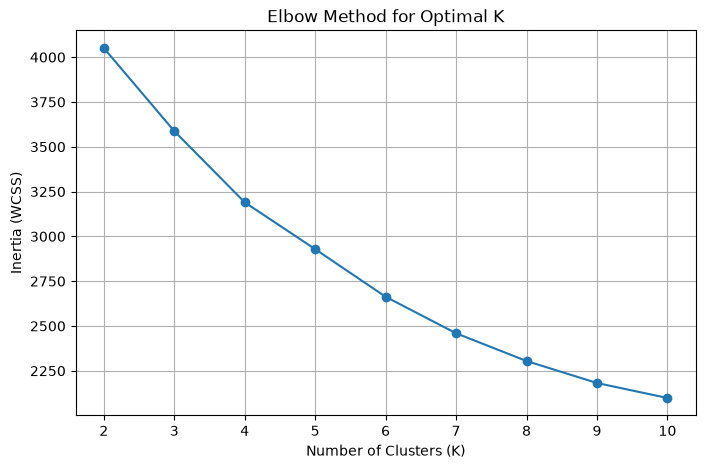

In [6]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Lưu giá trị inertia cho từng K
inertias = []

# Thử các giá trị K từ 1 đến 10
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_labeled)

    inertias.append(kmeans.inertia_)

# Vẽ Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(
    k_values,
    inertias,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for Optimal K")
plt.xticks(k_values)
plt.grid(True)

plt.show()

##### 5.2 Evaluate Clustering Quality Using Silhouette Score

In [7]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

silhouette_scores = []

k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_labeled)

    score = silhouette_score(
        X_labeled,
        labels
    )

    silhouette_scores.append(score)

# Hiển thị kết quả
for k, score in zip(k_values, silhouette_scores):
    print(f"K = {k}: {score:.4f}")

K = 2: 0.2555
K = 3: 0.1931
K = 4: 0.1794
K = 5: 0.1773
K = 6: 0.1791
K = 7: 0.1777
K = 8: 0.1848
K = 9: 0.1758
K = 10: 0.1751


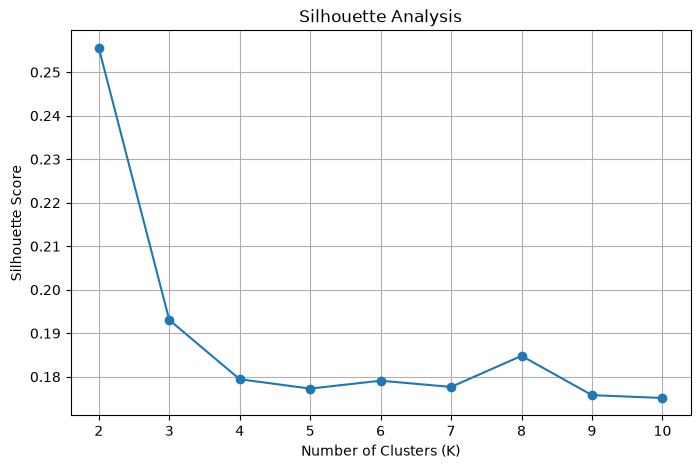

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.grid(True)

plt.show()

##### 5.3 Train K-MEANS model
Giả sử ta chọn k = 4


In [9]:
optimal_k = 4
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

labeled_clusters = kmeans.fit_predict(X_labeled)

#####
Dòng này tạo bản sao từ dataframe gốc và thêm 1 cột mới 'cluster' vào dataframe bản sao

In [10]:
labeled_cluster_df = labeled_df.copy()

labeled_cluster_df["cluster"] = labeled_clusters

In [11]:
labeled_cluster_df["cluster"].value_counts()

cluster
2    282
1    196
0    170
3    152
Name: count, dtype: int64

In [12]:
labeled_cluster_df

,all_util,bc_open_to_buy,percent_bc_gt_75,bc_util,annual_inc,loan_amnt,dti,term,grade,sub_grade,verification_status,home_ownership,int_rate,cluster
0,73.000000,8.992557,50.0,57.9,11.097425,16000,18.62,36 months,B,B3,Verified,MORTGAGE,10.42,2
1,83.000000,6.278521,100.0,83.4,10.933125,6000,11.74,36 months,C,C4,Not Verified,OWN,15.05,0
2,52.000000,10.053071,22.2,52.0,11.156265,15000,12.63,36 months,C,C1,Source Verified,OWN,12.74,1
3,56.173203,10.389365,33.3,44.5,11.512935,27000,10.63,36 months,A,A1,Not Verified,MORTGAGE,5.32,3
4,56.173203,7.655391,0.0,8.2,10.714440,1600,15.23,36 months,D,D1,Verified,MORTGAGE,15.61,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
993,56.173203,9.185330,66.7,68.2,11.034906,21800,19.20,36 months,D,D3,Verified,MORTGAGE,16.99,3
994,45.000000,7.901377,50.0,45.0,11.407576,12000,8.48,36 months,C,C2,Source Verified,MORTGAGE,13.59,1
996,74.000000,7.801391,100.0,96.1,12.358798,10000,26.35,36 months,B,B4,Source Verified,RENT,10.99,0
997,56.173203,7.721349,50.0,69.5,11.362114,20000,5.29,60 months,B,B2,Source Verified,MORTGAGE,10.15,3


#### 6. Calculate Mean `int_rate` for Each Cluster

Sau khi hoàn thành quá trình phân cụm, giá trị trung bình của biến mục tiêu
`int_rate` được tính cho từng cluster.

Ý tưởng của phương pháp này là các quan sát thuộc cùng một cluster có đặc
điểm tương đồng trong không gian đặc trưng, do đó chúng cũng có xu hướng
có mức lãi suất tương tự nhau.

Giá trị trung bình `int_rate` của mỗi cluster sẽ được sử dụng làm pseudo-label
cho các quan sát chưa có nhãn thuộc cùng cluster ở bước tiếp theo.

In [13]:
cluster_mean_rates = (
    labeled_cluster_df
    .groupby("cluster")["int_rate"]
    .mean()
)

cluster_mean_rates

cluster
0    14.320235
1    10.920612
2    13.011454
3    14.486118
Name: int_rate, dtype: float64

#### 7. Predict Cluster Membership for Unlabeled Data

Sau khi mô hình K-Means được huấn luyện trên tập dữ liệu có nhãn, các quan sát
chưa có nhãn (`unlabeled_df`) được đưa vào mô hình để xác định cluster mà chúng
thuộc về.

Mỗi quan sát sẽ được gán vào cluster có tâm cụm (cluster centroid) gần nhất
trong không gian đặc trưng đã được chuẩn hóa.

Kết quả của bước này là một mảng chứa cluster ID tương ứng với từng quan sát
chưa có nhãn.

In [14]:
unlabeled_clusters = kmeans.predict(X_unlabeled)

unlabeled_clusters[:10]

array([3, 2, 3, 2, 3, 0, 1, 2, 0, 0], dtype=int32)

#### 8. Assign Pseudo Labels

Sau khi xác định cluster của từng quan sát chưa có nhãn, giá trị trung bình
`int_rate` của cluster tương ứng được sử dụng làm pseudo-label.

Mỗi quan sát chưa có nhãn sẽ nhận giá trị trung bình `int_rate` của cluster mà
nó thuộc về.

Quá trình này cho phép tận dụng cấu trúc cụm được học từ dữ liệu có nhãn để
ước lượng nhãn cho các quan sát chưa có nhãn.

In [15]:
pseudo_labels = [
    cluster_mean_rates[cluster]
    for cluster in unlabeled_clusters
]

pseudo_labels[:10]

[np.float64(14.48611842105263),
 np.float64(13.01145390070922),
 np.float64(14.48611842105263),
 np.float64(13.01145390070922),
 np.float64(14.48611842105263),
 np.float64(14.320235294117648),
 np.float64(10.92061224489796),
 np.float64(13.01145390070922),
 np.float64(14.320235294117648),
 np.float64(14.320235294117648)]

#### 9. Create a Pseudo-Labeled Dataset

Các pseudo-label được gắn vào tập dữ liệu chưa có nhãn để tạo thành
pseudo-labeled dataset.

Tập dữ liệu này sẽ được sử dụng để đánh giá hiệu quả của phương pháp
K-Means Labeling.

In [16]:
unlabeled_result = unlabeled_df.copy()

unlabeled_result["pseudo_int_rate"] = pseudo_labels

unlabeled_result.head()

,all_util,bc_open_to_buy,percent_bc_gt_75,bc_util,annual_inc,loan_amnt,dti,term,grade,sub_grade,verification_status,home_ownership,int_rate,pseudo_int_rate
10,56.173203,9.442404,28.6,55.8,11.407576,30000,21.45,60 months,C,C2,Source Verified,MORTGAGE,NaN,14.486118
23,56.173203,6.834109,37.5,52.0,10.645449,7500,32.74,36 months,C,C5,Verified,RENT,NaN,13.011454
25,66.000000,8.563122,80.0,82.4,10.915107,24200,21.86,36 months,C,C2,Source Verified,MORTGAGE,NaN,14.486118
30,50.000000,9.588366,50.0,58.9,10.499601,15950,27.14,36 months,C,C2,Verified,OWN,NaN,13.011454
39,80.000000,8.355615,100.0,95.0,11.277216,24000,14.43,60 months,C,C4,Verified,RENT,NaN,14.486118


#### 10. Evaluate Pseudo Labeling Performance

Để đánh giá chất lượng gán nhãn của phương pháp K-Means Clustering,
các pseudo-label được so sánh với giá trị `int_rate` thực tế đã bị ẩn trước đó.

Hai chỉ số hồi quy được sử dụng:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)

Giá trị càng nhỏ cho thấy pseudo-label càng gần với nhãn thực tế.

In [17]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error

mae = mean_absolute_error(
    true_labels,
    pseudo_labels
)

rmse = root_mean_squared_error(
    true_labels,
    pseudo_labels
)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

MAE  : 4.0912
RMSE : 5.2802


#### So sánh các phương pháp gán nhãn

| Phương pháp | MAE |
|------------|------:|
| Summary Statistics + Euclidean Distance | 5.49 |
| K-Means Clustering (K = 4) | 4.09 |
| Pseudo-Labeling (Random Forest Regressor) | 3.49 |
